# Capstone — Prioritizing decline-labeled pages for editorial review

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This notebook consolidates Milestones 1–6 into one run that goes from the anonymized CSV to a ranked review queue. It is the source for `work/capstone_report.md` and the deployed paper (`docs/index.html`): every number there comes from `work/outputs/capstone_metrics.json`, which the last code cell writes.

**Scope, stated once and kept throughout:** the target is the supplied label `trend_direction == 'down'`. This is *exploratory ranking of pages carrying a supplied decline label* under client-held-out evaluation. It is not a validated early-warning system and not evidence that editing a page improves performance.

Run time: about 2–4 minutes on Colab (Runtime → Run all).

In [1]:
# Open from your FlyRank repository checkout, or clone it in Colab.
import os, sys, subprocess
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/huseyinTozluyurt/Flyrank-Internship-MachineLearning'
REPO_DIR = 'Flyrank-Internship-MachineLearning'
CSV_PATH = Path('data/raw/content_refresh_anonymized.csv')
if IN_COLAB and not CSV_PATH.exists():
    if not Path(REPO_DIR).is_dir():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
else:
    while not CSV_PATH.exists() and Path.cwd() != Path('/'):
        os.chdir('..')
if not CSV_PATH.exists():
    raise FileNotFoundError('Expected data/raw/content_refresh_anonymized.csv in the FlyRank repo.')
print('Repo root:', Path.cwd().name)

Repo root: flyrank-internship-machinelearning


In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore', category=FutureWarning)

OUTPUT_DIR = Path('work/outputs'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path('work/figures'); FIG_DIR.mkdir(parents=True, exist_ok=True)
PAPER_IMG_DIR = Path('docs/img'); PAPER_IMG_DIR.mkdir(parents=True, exist_ok=True)

# Fixed seeds. The first five grouped seeds (42-46) reproduce the Milestone 4 partitions.
PRIMARY_SEEDS = list(range(42, 62))   # 20 repeated client-held-out 75/25 splits
QUEUE_SEED, QUEUE_SPLITS = 42, 5      # Milestone 5 queue construction
TOP_K = 50
DEFAULT_MODEL = 'random_forest'      # default review queue (see Section 6); logistic queue kept for comparison
METRICS = {}                          # everything the report and paper quote

# Reference palette (validated categorical slots 1-3) plus a neutral for the rule baseline.
COLORS = {'logistic_regression': '#2a78d6', 'random_forest': '#eb6834',
          'static_only_logistic': '#1baf7a', 'heuristic_stale_traffic': '#8a8984'}
LABELS = {'logistic_regression': 'Logistic regression', 'random_forest': 'Random forest',
          'static_only_logistic': 'Age-only logistic (sensitivity)',
          'heuristic_stale_traffic': 'Stale + traffic rule'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10})
def save(fig, name):
    for d in (FIG_DIR, PAPER_IMG_DIR):
        fig.savefig(d / name, bbox_inches='tight', dpi=150)
    plt.show()

---
## 1. Question

*The research question and the decision it supports.*

**Question.** Can a handful of observable page signals, and lightweight models built on them, rank pages so that the top of an editor's review list is richer in pages carrying the supplied decline label than (a) the base rate and (b) the existing "stale and high-traffic" rule, **for clients the model has never seen**?

**Decision supported.** An editor at FlyRank has capacity to review roughly 50 pages per cycle. The output is an ordered review queue with plain reason codes. The editor decides what, if anything, to do with each page; nothing is changed automatically.

**Unit:** one `content_id` (page) within a `client_id`. **Output:** a rank. **Cost of a wrong call:** a false positive spends one review slot on a page that is not decline-labeled; a false negative leaves a decline-labeled page further down the backlog.

**Why ML at all?** The current rule uses two fields and ignores position and CTR. A model can weigh several weak signals together, but only a held-out comparison against the rule shows whether that helps.

---
## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

Source: the anonymized starter slice `data/raw/content_refresh_anonymized.csv` (one row per pseudonymized page, trailing-90-day metrics). The DuckDB warehouse release was not used in this run; see Limitations. Only aggregates are printed below: no client or page identifiers.

In [3]:
raw = pd.read_csv(CSV_PATH)
df = raw.copy()
df['trend_direction'] = df['trend_direction'].astype('string').str.strip().str.lower()
LABEL_MAP = {'down': 1, 'new': 0, 'up': 0, 'flat': 0, 'stable': 0}
df['is_declining_label'] = df['trend_direction'].map(LABEL_MAP).astype('Int64')

valid = (df['is_declining_label'].notna() & df['content_id'].notna() & df['client_id'].notna()
         & ~df['content_id'].duplicated(keep=False))
excluded = int((~valid).sum())
df = df.loc[valid].reset_index(drop=True)

audit = {
    'rows': int(len(raw)), 'columns': int(raw.shape[1]),
    'unique_pages': int(raw['content_id'].nunique()), 'clients': int(raw['client_id'].nunique()),
    'eligible_rows': int(len(df)), 'excluded_rows': excluded,
    'label_counts': {k: int(v) for k, v in df['trend_direction'].value_counts().items()},
    'base_rate': round(float(df['is_declining_label'].mean()), 4),
    'avg_position_zero_rows': int((raw['avg_position'] == 0).sum()),
    'missing_pct': {c: round(float(raw[c].isna().mean() * 100), 2)
                    for c in ['word_count', 'search_volume', 'trend_pct', 'days_since_last_update',
                              'content_age_days', 'impressions_90d', 'avg_position', 'ctr']},
}
per_client = df.groupby('client_id').agg(pages=('content_id', 'size'), base_rate=('is_declining_label', 'mean'))
audit['pages_per_client'] = {k: int(v) for k, v in per_client['pages'].describe()[['min', '50%', 'max']].items()}
audit['largest_client_share'] = round(float(per_client['pages'].max() / len(df)), 4)
audit['client_base_rate_range'] = [round(float(per_client['base_rate'].min()), 3),
                                   round(float(per_client['base_rate'].max()), 3)]
METRICS['audit'] = audit
print(json.dumps(audit, indent=2))

{
  "rows": 30000,
  "columns": 44,
  "unique_pages": 30000,
  "clients": 32,
  "eligible_rows": 30000,
  "excluded_rows": 0,
  "label_counts": {
    "down": 16262,
    "stable": 5962,
    "up": 4388,
    "new": 2236,
    "flat": 1152
  },
  "base_rate": 0.5421,
  "avg_position_zero_rows": 1205,
  "missing_pct": {
    "word_count": 25.66,
    "search_volume": 8.23,
    "trend_pct": 11.29,
    "days_since_last_update": 0.0,
    "content_age_days": 0.0,
    "impressions_90d": 0.0,
    "avg_position": 0.0,
    "ctr": 0.0
  },
  "pages_per_client": {
    "min": 3,
    "50%": 567,
    "max": 7008
  },
  "largest_client_share": 0.2336,
  "client_base_rate_range": [
    0.0,
    0.937
  ]
}


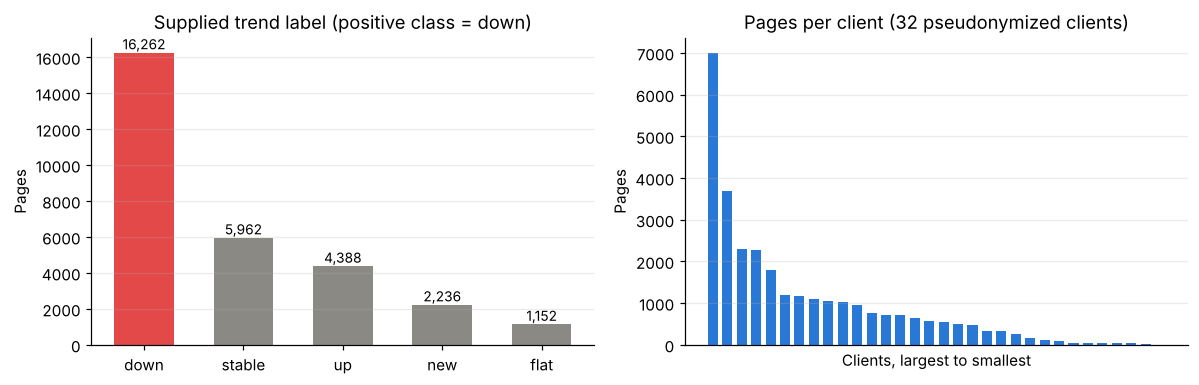

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = ['down', 'stable', 'up', 'new', 'flat']
counts = df['trend_direction'].value_counts().reindex(order)
axes[0].bar(order, counts.values, color=['#e34948'] + ['#8a8984'] * 4, width=0.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Supplied trend label (positive class = down)')
axes[0].set_ylabel('Pages'); axes[0].grid(axis='x', visible=False)
pc = per_client.sort_values('pages', ascending=False)
axes[1].bar(range(len(pc)), pc['pages'].values, color='#2a78d6', width=0.7)
axes[1].set_title('Pages per client (32 pseudonymized clients)')
axes[1].set_xlabel('Clients, largest to smallest'); axes[1].set_ylabel('Pages')
axes[1].set_xticks([]); axes[1].grid(axis='x', visible=False)
fig.tight_layout(); save(fig, 'fig1_data_overview.png')

Half the pages carry the decline label, so **any precision number must be read against a base rate of about 54%**. Client sizes are very uneven, which is why every evaluation below holds out whole clients and why results move depending on which clients are held out.

---
## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

- **Label:** `is_declining_label = 1` when `trend_direction == 'down'` (last-30-day impressions more than 20% below the previous 30 days), else 0.
- **Features (6):** `days_since_last_update`, `content_age_days`, `impressions_90d`, `avg_position`, `ctr`, and `days_since_last_update × avg_position`. `avg_position == 0` is recoded to missing.
- **Never features:** the label, `trend_direction`, `trend_pct`, the last-30/prev-30 window columns and change fields (they *are* the label arithmetic), and the pseudonymous IDs (grouping only).
- **Preprocessing:** median imputation plus missing-value indicators, and scaling for logistic regression, all fitted **inside each training split** (Milestone 2 chose this; it is re-checked below).
- **Baseline:** the existing rule: pages not updated for more than 180 days, ordered by 90-day impressions.
- **Validation:** 20 repeated 75/25 `GroupShuffleSplit` partitions by `client_id` (seeds 42–61; 42–46 reproduce Milestone 4). Every candidate is scored on the identical held-out rows of each split. A stratified random page split is run only as a diagnostic.
- **Known window overlap:** `impressions_90d`, `ctr` and `avg_position` are computed over a 90-day window that **contains** the 30-day label window. They can partly reflect the decline itself. A sensitivity model that uses only the two age fields (which do not overlap the label window) shows how much of the signal survives without them.
- **Position-missing artifact:** pages with `avg_position == 0` are almost all labeled `new`, so the missing-position indicator is a near-mechanical marker of a non-decline label. A second sensitivity run drops those pages.

In [5]:
BASE_FEATURES = ['days_since_last_update', 'content_age_days', 'impressions_90d', 'avg_position', 'ctr']
X = df[BASE_FEATURES].apply(pd.to_numeric, errors='coerce').copy()
X['avg_position'] = X['avg_position'].mask(X['avg_position'].eq(0))
X['staleness_pos_interaction'] = X['days_since_last_update'] * X['avg_position']
FEATURES = list(X.columns)
STATIC_FEATURES = ['days_since_last_update', 'content_age_days']   # no overlap with the label window
y = df['is_declining_label'].astype(int)
groups = df['client_id']

FORBIDDEN = {'trend_direction', 'is_declining_label', 'trend_pct', 'impressions_change_pct', 'clicks_change_pct',
             'current_period_impressions', 'previous_period_impressions', 'content_id', 'client_id'}
FORBIDDEN |= {c for c in raw.columns if c.endswith('_last_30d') or c.endswith('_prev_30d')}
assert not (set(FEATURES) & FORBIDDEN), 'A label-derived field or ID entered the feature set.'

# Leakage probe: how well does each single feature rank the label on its own (pooled AUC, direction-free)?
probe = {}
for c in FEATURES:
    s = X[c].fillna(X[c].median())
    auc = roc_auc_score(y, s)
    probe[c] = round(max(auc, 1 - auc), 3)
probe['trend_pct (forbidden, shown for contrast)'] = round(roc_auc_score(y, -df['trend_pct'].fillna(0)), 3)
METRICS['single_feature_auc'] = probe
print('Features:', FEATURES)
print('Single-feature AUC (0.5 = no signal):')
print(pd.Series(probe).sort_values(ascending=False).to_string())

Features: ['days_since_last_update', 'content_age_days', 'impressions_90d', 'avg_position', 'ctr', 'staleness_pos_interaction']
Single-feature AUC (0.5 = no signal):
trend_pct (forbidden, shown for contrast)    1.000
content_age_days                             0.591
impressions_90d                              0.584
days_since_last_update                       0.527
ctr                                          0.515
avg_position                                 0.514
staleness_pos_interaction                    0.505


No allowed feature comes close to the forbidden `trend_pct`, which separates the label perfectly by construction. That is the expected picture when no direct label leak is present. It does not rule out the subtler window overlap described above.

In [6]:
def build_model(kind, seed):
    imp = ('imputer', SimpleImputer(strategy='median', add_indicator=True))
    if kind in ('logistic_regression', 'static_only_logistic'):
        return Pipeline([imp, ('scale', StandardScaler()),
                         ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=seed))])
    return Pipeline([imp, ('model', RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=2,
                                                           class_weight='balanced', random_state=seed, n_jobs=-1))])

def heuristic_score(frame):
    stale = pd.to_numeric(frame['days_since_last_update'], errors='coerce').fillna(-1).gt(180).astype(int)
    return (stale * pd.to_numeric(frame['impressions_90d'], errors='coerce').fillna(0).clip(lower=0)).to_numpy()

def precision_at_k(scores, labels, k):
    labels = np.asarray(labels); n = min(k, len(labels))
    return float(labels[np.argsort(-np.asarray(scores), kind='stable')[:n]].mean())

def score_metrics(y_true, scores, probs=None):
    base = float(np.mean(y_true))
    out = {'average_precision': average_precision_score(y_true, scores),
           'roc_auc': roc_auc_score(y_true, scores),
           'precision_at_20': precision_at_k(scores, y_true, 20),
           'precision_at_50': precision_at_k(scores, y_true, 50),
           'precision_at_100': precision_at_k(scores, y_true, 100),
           'base_rate': base}
    out['lift_at_50'] = out['precision_at_50'] / base
    out['brier'] = brier_score_loss(y_true, probs) if probs is not None else np.nan
    return out

CANDIDATES = ['heuristic_stale_traffic', 'logistic_regression', 'random_forest', 'static_only_logistic']
def evaluate(train_idx, test_idx, seed):
    rows, preds = [], {}
    y_te = y.iloc[test_idx].to_numpy()
    for name in CANDIDATES:
        if name == 'heuristic_stale_traffic':
            s = heuristic_score(df.iloc[test_idx]); p = None
        else:
            cols = STATIC_FEATURES if name == 'static_only_logistic' else FEATURES
            m = build_model(name, seed).fit(X.iloc[train_idx][cols], y.iloc[train_idx])
            s = p = m.predict_proba(X.iloc[test_idx][cols])[:, 1]
        preds[name] = s
        rows.append({'model': name, **score_metrics(y_te, s, p)})
    return rows, preds

### Preprocessing re-check (Milestone 2)

Complete-case rows vs. train-fold median imputation vs. median plus missingness indicators, logistic regression, first five grouped seeds.

In [7]:
pre_rows = []
for seed in PRIMARY_SEEDS[:5]:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(X, y, groups))
    for strat in ['complete_case', 'median', 'median_plus_indicators']:
        Xtr, ytr, Xte, yte = X.iloc[tr], y.iloc[tr], X.iloc[te], y.iloc[te]
        if strat == 'complete_case':
            keep_tr, keep_te = Xtr.notna().all(axis=1), Xte.notna().all(axis=1)
            Xtr, ytr, Xte, yte = Xtr[keep_tr], ytr[keep_tr], Xte[keep_te], yte[keep_te]
        pipe = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=(strat == 'median_plus_indicators'))),
                         ('scale', StandardScaler()),
                         ('model', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=seed))])
        s = pipe.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        pre_rows.append({'strategy': strat, 'seed': seed, 'test_rows': len(yte),
                         'average_precision': average_precision_score(yte, s),
                         'precision_at_50': precision_at_k(s, yte, 50)})
pre = pd.DataFrame(pre_rows).groupby('strategy')[['test_rows', 'average_precision', 'precision_at_50']].mean().round(3)
METRICS['preprocessing'] = pre.reset_index().to_dict(orient='records')
pre

,test_rows,average_precision,precision_at_50
strategy,,,
complete_case,9729.6,0.654,0.748
median,9854.6,0.645,0.676
median_plus_indicators,9854.6,0.654,0.748


---
## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [8]:
fold_rows, fold_preds = [], []
for seed in PRIMARY_SEEDS:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(X, y, groups))
    assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te]), 'Client overlap in a grouped split.'
    rows, preds = evaluate(tr, te, seed)
    for r in rows:
        r.update(seed=seed, design='client_grouped', test_clients=groups.iloc[te].nunique(), test_rows=len(te))
    fold_rows += rows
    fp = df.iloc[te][['client_id', 'trend_direction']].copy()
    fp['label'] = y.iloc[te].to_numpy(); fp['seed'] = seed
    for name, s in preds.items():
        fp[name] = s
    fold_preds.append(fp)
grouped = pd.DataFrame(fold_rows)
grouped_preds = pd.concat(fold_preds, ignore_index=True)

cols = ['average_precision', 'roc_auc', 'precision_at_20', 'precision_at_50', 'precision_at_100', 'lift_at_50', 'brier']
summary = grouped.groupby('model')[cols].agg(['mean', 'std', 'min', 'max'])
summary = summary.loc[CANDIDATES]
summary.columns = [f'{a}_{b}' for a, b in summary.columns]
METRICS['grouped_summary'] = {m: {k: round(float(v), 4) for k, v in r.items() if pd.notna(v)} for m, r in summary.iterrows()}
METRICS['grouped_base_rate_mean'] = round(float(grouped['base_rate'].mean()), 4)
METRICS['grouped_test_clients_mean'] = round(float(grouped['test_clients'].mean()), 2)
print(f"20 client-held-out splits; mean held-out base rate = {grouped['base_rate'].mean():.3f}; "
      f"~{grouped['test_clients'].mean():.0f} held-out clients per split")
summary[[c for c in summary.columns if c.endswith('_mean')]].round(3)

20 client-held-out splits; mean held-out base rate = 0.581; ~8 held-out clients per split


,average_precision_mean,roc_auc_mean,precision_at_20_mean,precision_at_50_mean,precision_at_100_mean,lift_at_50_mean,brier_mean
model,,,,,,,
heuristic_stale_traffic,0.581,0.500,0.702,0.660,0.638,1.135,NaN
logistic_regression,0.664,0.614,0.768,0.770,0.772,1.329,0.234
random_forest,0.683,0.638,0.752,0.754,0.768,1.311,0.227
static_only_logistic,0.647,0.588,0.665,0.697,0.690,1.198,0.244


In [9]:
# Milestone 4 reproduction check: seeds 42-46 only.
m4 = grouped[grouped['seed'].isin(PRIMARY_SEEDS[:5])].groupby('model')[['average_precision', 'precision_at_50']].mean().round(3)
METRICS['milestone4_seeds_42_46'] = m4.reset_index().to_dict(orient='records')
m4.loc[CANDIDATES]

,average_precision,precision_at_50
model,,
heuristic_stale_traffic,0.582,0.680
logistic_regression,0.654,0.748
random_forest,0.663,0.724
static_only_logistic,0.638,0.656


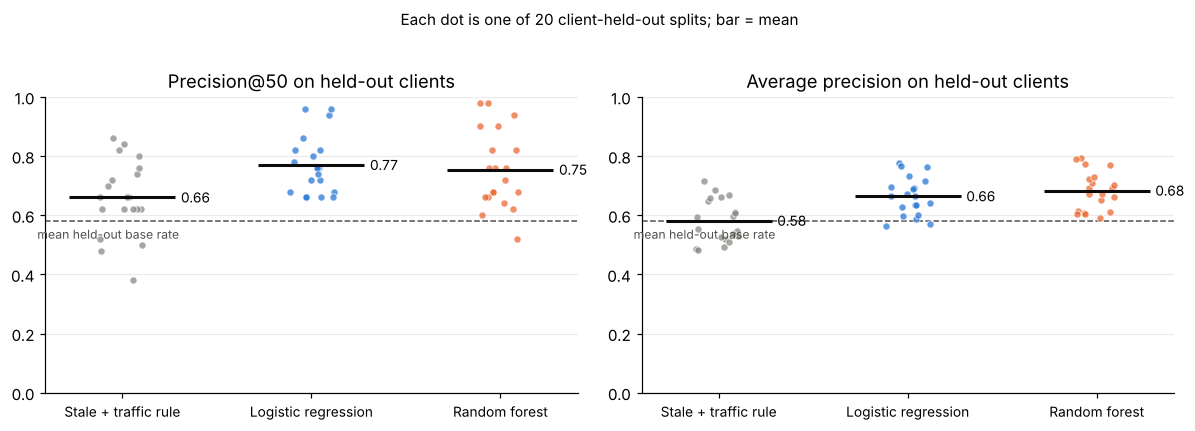

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
show = ['heuristic_stale_traffic', 'logistic_regression', 'random_forest']
for ax, metric, title in [(axes[0], 'precision_at_50', 'Precision@50 on held-out clients'),
                          (axes[1], 'average_precision', 'Average precision on held-out clients')]:
    data = [grouped.loc[grouped['model'] == m, metric].to_numpy() for m in show]
    rng = np.random.default_rng(0)
    for i, (m, d) in enumerate(zip(show, data)):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=22, color=COLORS[m], alpha=0.75,
                   edgecolor='white', linewidth=0.6, zorder=3)
        ax.hlines(d.mean(), i - 0.28, i + 0.28, color='#0b0b0b', linewidth=2, zorder=4)
        ax.text(i + 0.31, d.mean(), f'{d.mean():.2f}', va='center', fontsize=9)
    ax.axhline(grouped['base_rate'].mean(), color='#52514e', linestyle='--', linewidth=1)
    ax.text(-0.45, grouped['base_rate'].mean() - 0.02, 'mean held-out base rate', fontsize=8, color='#52514e',
            ha='left', va='top')
    ax.set_xticks(range(len(show))); ax.set_xticklabels([LABELS[m] for m in show], fontsize=9)
    ax.set_title(title); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
fig.suptitle('Each dot is one of 20 client-held-out splits; bar = mean', fontsize=10, y=1.02)
fig.tight_layout(); save(fig, 'fig2_model_vs_baseline.png')

### Paired comparison and split-design diagnostic

In [11]:
wide = grouped.pivot(index='seed', columns='model', values=['precision_at_50', 'average_precision'])
paired = {}
for metric in ['precision_at_50', 'average_precision']:
    for a, b in [('logistic_regression', 'heuristic_stale_traffic'), ('random_forest', 'heuristic_stale_traffic'),
                 ('random_forest', 'logistic_regression'), ('logistic_regression', 'static_only_logistic')]:
        d = wide[metric][a] - wide[metric][b]
        paired[f'{metric}: {a} - {b}'] = {'mean_delta': round(float(d.mean()), 4), 'sd_delta': round(float(d.std()), 4),
                                          'splits_a_wins': int((d > 0).sum()), 'splits': int(d.size)}
METRICS['paired_deltas'] = paired
pd.DataFrame(paired).T

,mean_delta,sd_delta,splits_a_wins,splits
precision_at_50: logistic_regression - heuristic_stale_traffic,0.1100,0.0832,19.0,20.0
precision_at_50: random_forest - heuristic_stale_traffic,0.0940,0.1594,14.0,20.0
precision_at_50: random_forest - logistic_regression,-0.0160,0.1304,9.0,20.0
precision_at_50: logistic_regression - static_only_logistic,0.0730,0.0930,16.0,20.0
average_precision: logistic_regression - heuristic_stale_traffic,0.0828,0.0273,20.0,20.0
average_precision: random_forest - heuristic_stale_traffic,0.1018,0.0305,20.0,20.0
average_precision: random_forest - logistic_regression,0.0190,0.0217,16.0,20.0
average_precision: logistic_regression - static_only_logistic,0.0169,0.0248,14.0,20.0


### Sensitivity: pages with position data only

The 1,205 pages with `avg_position == 0` are almost all labeled `new` (no impressions in the earlier 30-day window), so "position missing" is close to a mechanical marker of a non-decline label. The check below drops those pages and re-runs the same 20 grouped splits, to see how much of the result rests on these easy negatives.

In [12]:
pos_idx = np.where(X['avg_position'].notna())[0]
print('Label mix where avg_position == 0:', df.loc[X['avg_position'].isna(), 'trend_direction'].value_counts(normalize=True).round(3).to_dict())
sens_rows = []
for seed in PRIMARY_SEEDS:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(pos_idx, groups=groups.iloc[pos_idx]))
    rows, _ = evaluate(pos_idx[tr], pos_idx[te], seed)
    for r in rows: r['seed'] = seed
    sens_rows += rows
sens = pd.DataFrame(sens_rows).groupby('model')[['base_rate', 'average_precision', 'roc_auc', 'precision_at_50', 'lift_at_50']].mean().loc[CANDIDATES].round(3)
sw = pd.DataFrame(sens_rows).pivot(index='seed', columns='model', values='precision_at_50')
d = sw['random_forest'] - sw['logistic_regression']
METRICS['position_available_subset'] = {'rows': int(len(pos_idx)), **{m: r.to_dict() for m, r in sens.iterrows()},
    'p50_rf_minus_lr': {'mean_delta': float(d.mean()), 'sd_delta': float(d.std()), 'rf_wins': int((d > 0).sum()),
                        'ties': int((d == 0).sum()), 'splits': int(d.size)}}
print(f'Precision@50, random forest minus logistic: mean {d.mean():+.3f}; forest higher in {(d > 0).sum()} of {d.size} splits')
sens

Label mix where avg_position == 0: {'new': 0.958, 'flat': 0.036, 'down': 0.007}


Precision@50, random forest minus logistic: mean +0.168; forest higher in 18 of 20 splits


,base_rate,average_precision,roc_auc,precision_at_50,lift_at_50
model,,,,,
heuristic_stale_traffic,0.551,0.552,0.500,0.568,1.033
logistic_regression,0.551,0.618,0.592,0.606,1.103
random_forest,0.551,0.668,0.645,0.774,1.410
static_only_logistic,0.551,0.615,0.589,0.669,1.207


In [13]:
rand_rows = []
for seed in PRIMARY_SEEDS[:5]:
    tr, te = next(StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(X, y))
    rows, _ = evaluate(tr, te, seed)
    overlap = len(set(groups.iloc[tr]) & set(groups.iloc[te]))
    for r in rows:
        r.update(seed=seed, overlapping_clients=overlap)
    rand_rows += rows
rand = pd.DataFrame(rand_rows)
diag = pd.concat({
    'random_page_split (diagnostic)': rand.groupby('model')[['average_precision', 'roc_auc', 'precision_at_50']].mean(),
    'client_grouped (primary)': grouped[grouped['seed'].isin(PRIMARY_SEEDS[:5])].groupby('model')[['average_precision', 'roc_auc', 'precision_at_50']].mean(),
}).round(3)
METRICS['split_diagnostic'] = {f'{d}|{m}': r.to_dict() for (d, m), r in diag.iterrows()}
METRICS['random_split_overlapping_clients_mean'] = float(rand['overlapping_clients'].mean())
print(f"Random page split: on average {rand['overlapping_clients'].mean():.0f} of 32 clients appear on both sides.")
diag

Random page split: on average 31 of 32 clients appear on both sides.


average_precision  \
                               model                                        
random_page_split (diagnostic) heuristic_stale_traffic              0.543   
                               logistic_regression                  0.656   
                               random_forest                        0.727   
                               static_only_logistic                 0.624   
client_grouped (primary)       heuristic_stale_traffic              0.582   
                               logistic_regression                  0.654   
                               random_forest                        0.663   
                               static_only_logistic                 0.638   

                                                        roc_auc  \
                               model                              
random_page_split (diagnostic) heuristic_stale_traffic    0.499   
                               logistic_regression        0.657   
                               random_forest              0.719   
                               static_only_logistic       0.609   
client_grouped (primary)       heuristic_stale_traffic    0.501   
                               logistic_regression        0.605   
                               random_forest              0.611   
                               static_only_logistic       0.582   

                                                        precision_at_50  
                               model                                     
random_page_split (diagnostic) heuristic_stale_traffic            0.468  
                               logistic_regression                0.752  
                               random_forest                      0.852  
                               static_only_logistic               0.732  
client_grouped (primary)       heuristic_stale_traffic            0.680  
                               logistic_regression                0.748  
                               random_forest                      0.724  
                               static_only_logistic               0.656

### Error analysis

In [14]:
# What do the top-50 misses carry, per model? (pooled over the 20 splits)
miss_rows = []
for seed, g in grouped_preds.groupby('seed'):
    for m in ['heuristic_stale_traffic', 'logistic_regression', 'random_forest']:
        top = g.sort_values(m, ascending=False, kind='stable').head(TOP_K)
        for lab, n in top['trend_direction'].value_counts().items():
            miss_rows.append({'model': m, 'label': lab, 'pages': n})
mix = (pd.DataFrame(miss_rows).groupby(['model', 'label'])['pages'].sum().unstack(fill_value=0))
mix = (mix.div(mix.sum(axis=1), axis=0) * 100).round(1)
METRICS['top50_label_mix_pct'] = mix.to_dict(orient='index')
print('Label mix of the top 50, % of selected pages (down = hit):')
mix

Label mix of the top 50, % of selected pages (down = hit):


label,down,flat,new,stable,up
model,,,,,
heuristic_stale_traffic,66.0,2.1,2.9,14.1,14.9
logistic_regression,77.0,7.0,1.6,6.5,7.9
random_forest,75.4,0.1,2.7,13.9,7.9


In [15]:
# Client-level variation: how does the logistic queue do inside each held-out client?
client_rows = []
for (seed, client), g in grouped_preds.groupby(['seed', 'client_id']):
    if len(g) < 30 or g['label'].nunique() < 2:
        continue
    for m in ['heuristic_stale_traffic', 'logistic_regression', 'random_forest']:
        client_rows.append({'model': m, 'seed': seed, 'client': client,
                            'auc': roc_auc_score(g['label'], g[m]), 'base_rate': g['label'].mean(), 'pages': len(g)})
cl = pd.DataFrame(client_rows).groupby(['model', 'client'])[['auc', 'base_rate', 'pages']].mean().reset_index()
client_summary = cl.groupby('model')['auc'].describe()[['count', 'min', '25%', '50%', '75%', 'max']].round(3)
client_summary['share_below_0.5'] = cl.groupby('model')['auc'].apply(lambda s: round(float((s < 0.5).mean()), 3))
METRICS['within_client_auc'] = client_summary.to_dict(orient='index')
print('Within-client ROC AUC across held-out clients with >= 30 pages (client identities not shown):')
client_summary

Within-client ROC AUC across held-out clients with >= 30 pages (client identities not shown):


,count,min,25%,50%,75%,max,share_below_0.5
model,,,,,,,
heuristic_stale_traffic,29.0,0.495,0.500,0.500,0.500,0.538,0.138
logistic_regression,29.0,0.435,0.527,0.548,0.599,0.738,0.138
random_forest,29.0,0.496,0.573,0.614,0.684,0.804,0.034


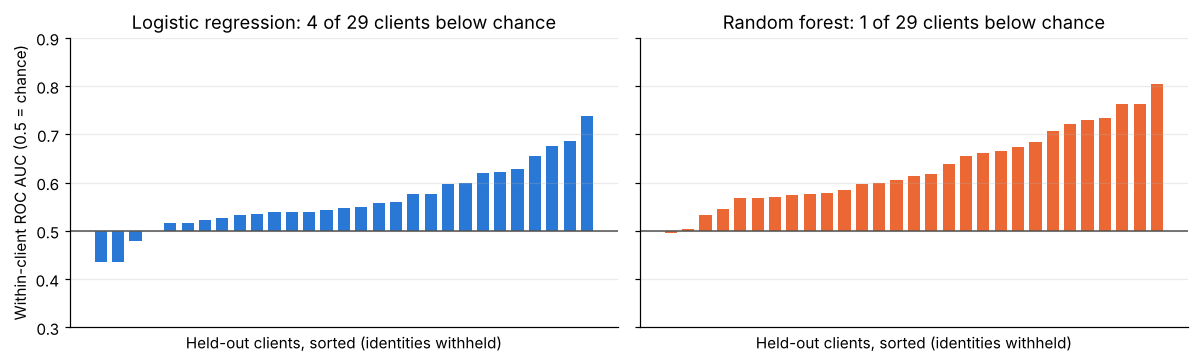

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, m in zip(axes, ['logistic_regression', 'random_forest']):
    mc = cl[cl['model'] == m].sort_values('auc')
    ax.bar(range(len(mc)), mc['auc'] - 0.5, bottom=0.5, color=COLORS[m], width=0.7)
    ax.axhline(0.5, color='#52514e', linewidth=1)
    ax.set_xticks([]); ax.set_xlabel('Held-out clients, sorted (identities withheld)')
    ax.set_ylim(0.3, 0.9); ax.grid(axis='x', visible=False)
    ax.set_title(f"{LABELS[m]}: {(mc['auc'] < 0.5).sum()} of {len(mc)} clients below chance")
axes[0].set_ylabel('Within-client ROC AUC (0.5 = chance)')
fig.tight_layout(); save(fig, 'fig3_client_variation.png')

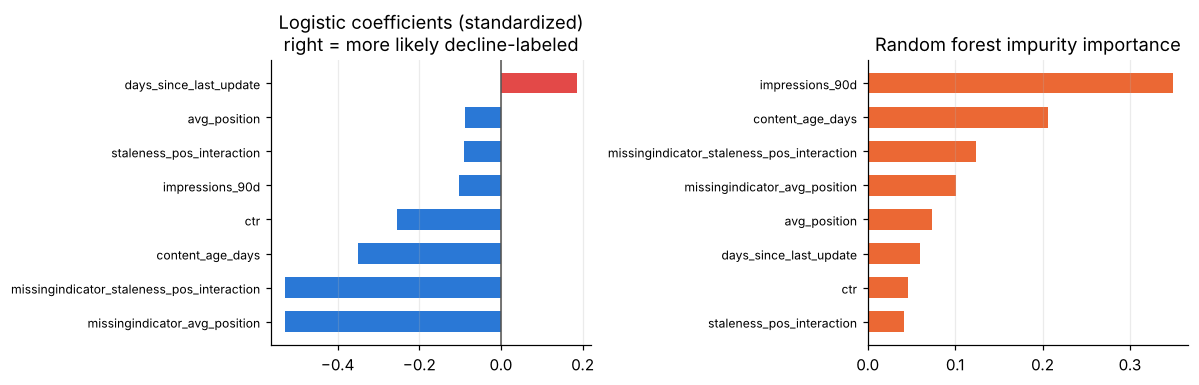

In [17]:
# Interpretation: standardized logistic coefficients (fit on all rows, for description only).
full_lr = build_model('logistic_regression', 42).fit(X, y)
names = full_lr.named_steps['imputer'].get_feature_names_out(FEATURES)
coef = pd.Series(full_lr.named_steps['model'].coef_[0], index=names).sort_values()
METRICS['logistic_coefficients'] = coef.round(3).to_dict()
full_rf = build_model('random_forest', 42).fit(X, y)
imp = pd.Series(full_rf.named_steps['model'].feature_importances_, index=names).sort_values()
METRICS['forest_importances'] = imp.round(3).to_dict()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(coef.index, coef.values, color=np.where(coef.values > 0, '#e34948', '#2a78d6'), height=0.6)
axes[0].axvline(0, color='#52514e', linewidth=1)
axes[0].set_title('Logistic coefficients (standardized)\nright = more likely decline-labeled')
axes[1].barh(imp.index, imp.values, color='#eb6834', height=0.6)
axes[1].set_title('Random forest impurity importance')
for ax in axes: ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=8)
fig.tight_layout(); save(fig, 'fig4_feature_signals.png')

---
## 5. Limitations

*What this work cannot claim.*

1. **Current-label task only.** The label marks pages *already* down (last 30 days vs the 30 before). Nothing here shows the system can warn before a decline.
2. **Feature windows overlap the label window.** `impressions_90d`, `ctr` and `avg_position` include the label's 30 days. The age-only sensitivity model shows how much ranking survives without them; the rest may partly reflect the decline itself rather than precede it.
3. **Feature dates are unverified in the CSV.** Only dated warehouse records (DuckDB release) can confirm that every feature precedes the label period. That validation (Milestone 7) has not been run.
4. **32 clients, very uneven in size.** Held-out results swing with which clients are held out, and within-client ranking is worse than chance for a share of clients. Repeated splits overlap, so the spread is descriptive, not a significance test.
5. **Scores are not calibrated probabilities.** Class weighting shifts them; use them only as ranks.
6. **Reason codes are threshold rules on observed fields,** not causal mechanisms and not explanations of an individual score.
7. **No outcome measurement.** Nothing here measures whether reviewing or editing a queued page changes its performance.

---
## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The queue follows Milestone 5: five client-held-out partitions (seed 42); each page is scored only by models that never saw its client; pages are ranked by how often they reach the per-fold top 50, then by mean rank percentile. **Random forest is the default queue in the capstone.** Milestone 5 chose logistic regression for its higher grouped Precision@50, but Section 4 shows that edge is a near-tie over 20 splits and disappears once the position-missing pages are removed, while the forest's top-50 precision holds. The logistic queue is still exported for comparison. The full queues are written to `work/outputs/` (gitignored, not published).

In [18]:
gss = GroupShuffleSplit(n_splits=QUEUE_SPLITS, test_size=0.25, random_state=QUEUE_SEED)
rows = []
for split_id, (tr, te) in enumerate(gss.split(X, y, groups), start=1):
    assert set(groups.iloc[tr]).isdisjoint(groups.iloc[te])
    for m in ['logistic_regression', 'random_forest']:
        s = build_model(m, QUEUE_SEED).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        f = df.iloc[te][['content_id', 'client_id', 'trend_direction', 'is_declining_label'] + BASE_FEATURES].copy()
        f['split'], f['model'], f['priority_score'] = split_id, m, s
        f['rank'] = f['priority_score'].rank(method='first', ascending=False).astype(int)
        f['rank_percentile'] = f['rank'] / len(f)
        f['top_50'] = f['rank'].le(TOP_K)
        rows.append(f)
held = pd.concat(rows, ignore_index=True)
first = {c: (c, 'first') for c in ['trend_direction', 'is_declining_label'] + BASE_FEATURES}
consensus = held.groupby(['model', 'content_id', 'client_id'], as_index=False).agg(
    heldout_appearances=('split', 'nunique'), top_50_rate=('top_50', 'mean'),
    mean_rank_percentile=('rank_percentile', 'mean'), mean_priority_score=('priority_score', 'mean'), **first)
consensus['avg_position'] = consensus['avg_position'].mask(consensus['avg_position'].eq(0))

hv = consensus['impressions_90d'].quantile(0.75)
def reason_codes(r):
    out = []
    if pd.isna(r['avg_position']): out.append('POSITION_DATA_MISSING_CHECK_GSC')
    elif 6 <= r['avg_position'] <= 22: out.append('POSITION_DANGER_BAND_REVIEW_SERP')
    if r['days_since_last_update'] > 180:
        out.append('STALE_WITH_TRAFFIC_REVIEW_UPDATE_HISTORY' if r['impressions_90d'] > 0 else 'STALE_PAGE_CHECK_VALUE_AND_STATUS')
    if r['impressions_90d'] >= hv: out.append('HIGH_VISIBILITY_VALIDATE_IMPACT')
    return ';'.join(out) or 'MODEL_PRIORITY_REVIEW_CONTEXT_FIRST'
consensus['reason_codes'] = consensus.apply(reason_codes, axis=1)

def build_queue(m):
    q = consensus[consensus['model'] == m].sort_values(
        ['top_50_rate', 'mean_rank_percentile', 'mean_priority_score'], ascending=[False, True, False]).reset_index(drop=True)
    q.insert(0, 'queue_rank', np.arange(1, len(q) + 1))
    q['review_tier'] = np.select([q['queue_rank'] <= 20, q['queue_rank'] <= 50], ['TOP_20_REVIEW', 'NEXT_30_REVIEW'], 'BACKLOG')
    q['recommendation_status'] = 'HUMAN_REVIEW_REQUIRED'
    return q
queues = {m: build_queue(m) for m in ['logistic_regression', 'random_forest']}
for m, q in queues.items():
    q.to_csv(OUTPUT_DIR / f'capstone_{m}_review_queue.csv', index=False)   # gitignored

lr_top, rf_top = queues['logistic_regression'].head(TOP_K), queues['random_forest'].head(TOP_K)
default_top = queues[DEFAULT_MODEL].head(TOP_K)
codes = default_top['reason_codes'].str.get_dummies(sep=';').sum().sort_values(ascending=False)
METRICS['queue'] = {
    'candidate_pages': int(queues['logistic_regression'].shape[0]),
    'lr_top50_decline_labeled_share': round(float(lr_top['is_declining_label'].mean()), 3),
    'rf_top50_decline_labeled_share': round(float(rf_top['is_declining_label'].mean()), 3),
    'candidate_base_rate': round(float(queues['logistic_regression']['is_declining_label'].mean()), 3),
    'top50_overlap_pages': int(len(set(lr_top['content_id']) & set(rf_top['content_id']))),
    'default_model': DEFAULT_MODEL,
    'default_top50_clients': int(default_top['client_id'].nunique()),
    'default_top50_largest_client_share': round(float(default_top['client_id'].value_counts(normalize=True).iloc[0]), 3),
    'default_top50_reason_code_counts': {k: int(v) for k, v in codes.items()},
}
print(json.dumps(METRICS['queue'], indent=2))

{
  "candidate_pages": 20012,
  "lr_top50_decline_labeled_share": 0.74,
  "rf_top50_decline_labeled_share": 0.84,
  "candidate_base_rate": 0.547,
  "top50_overlap_pages": 5,
  "default_model": "random_forest",
  "default_top50_clients": 6,
  "default_top50_largest_client_share": 0.4,
  "default_top50_reason_code_counts": {
    "HIGH_VISIBILITY_VALIDATE_IMPACT": 33,
    "MODEL_PRIORITY_REVIEW_CONTEXT_FIRST": 11,
    "POSITION_DANGER_BAND_REVIEW_SERP": 7
  }
}


The top-50 label share above is descriptive only: it is computed on the same held-out predictions that built the queue, so it is not a fresh estimate. Use Section 4 for performance.

In [19]:
# The first rows of the default queue (pseudonymous page IDs only; client IDs withheld from display).
show_cols = ['queue_rank', 'review_tier', 'content_id', 'top_50_rate', 'days_since_last_update',
             'impressions_90d', 'avg_position', 'ctr', 'reason_codes']
queues[DEFAULT_MODEL][show_cols].head(10)

,queue_rank,review_tier,content_id,top_50_rate,days_since_last_update,impressions_90d,avg_position,ctr,reason_codes
0,1,TOP_20_REVIEW,content_bb0d0d5e8148,1.0,14,10330,42.6,0.04,HIGH_VISIBILITY_VALIDATE_IMPACT
1,2,TOP_20_REVIEW,content_26d48a980581,1.0,106,1266,4.6,0.00,MODEL_PRIORITY_REVIEW_CONTEXT_FIRST
2,3,TOP_20_REVIEW,content_21b3d827d451,1.0,14,38894,39.4,0.01,HIGH_VISIBILITY_VALIDATE_IMPACT
3,4,TOP_20_REVIEW,content_df1ea55eabf9,1.0,8,13745,43.8,0.04,HIGH_VISIBILITY_VALIDATE_IMPACT
4,5,TOP_20_REVIEW,content_7c2bbd5f1b11,1.0,8,9293,39.7,0.04,HIGH_VISIBILITY_VALIDATE_IMPACT
5,6,TOP_20_REVIEW,content_829c68e60d13,1.0,106,307,4.9,0.00,MODEL_PRIORITY_REVIEW_CONTEXT_FIRST
6,7,TOP_20_REVIEW,content_945098c8e5e1,1.0,20,4888,28.6,0.04,HIGH_VISIBILITY_VALIDATE_IMPACT
7,8,TOP_20_REVIEW,content_f71530345803,1.0,20,5010,31.0,0.06,HIGH_VISIBILITY_VALIDATE_IMPACT
8,9,TOP_20_REVIEW,content_323d0bdf7077,1.0,106,2018,4.6,0.05,MODEL_PRIORITY_REVIEW_CONTEXT_FIRST
9,10,TOP_20_REVIEW,content_dc55d7e3c008,1.0,8,14131,40.1,0.02,HIGH_VISIBILITY_VALIDATE_IMPACT


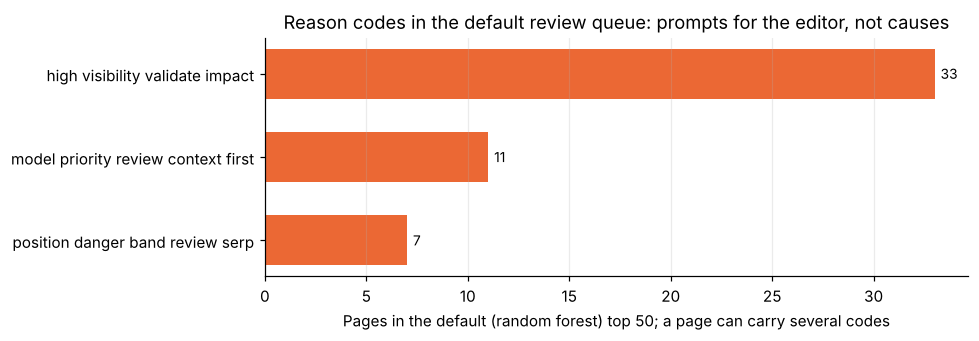

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.2))
pretty = codes.rename(lambda s: s.replace('_', ' ').lower())
ax.barh(pretty.index[::-1], pretty.values[::-1], color=COLORS[DEFAULT_MODEL], height=0.6)
for i, v in enumerate(pretty.values[::-1]):
    ax.text(v + 0.3, i, str(v), va='center', fontsize=9)
ax.set_xlabel('Pages in the default (random forest) top 50; a page can carry several codes')
ax.set_title('Reason codes in the default review queue: prompts for the editor, not causes')
ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, 'fig5_reason_codes.png')

**How an editor uses the queue tomorrow**

1. Work the `TOP_20_REVIEW` tier first, then `NEXT_30_REVIEW`.
2. Read the reason codes as a checklist: *position danger band* → look at the SERP and competing pages; *stale with traffic* → check update history and accuracy; *high visibility* → confirm the traffic drop is real before acting; *position data missing* → check Search Console coverage first.
3. Before any action, check seasonality, indexing/technical health, intent match, and whether the page should stay live.
4. Never bulk-edit, delete, or redirect from the queue. Log what was reviewed and what was done so outcomes can be measured later.

---
## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Charts are saved to `work/figures/` and copied to `docs/img/` for the paper. The metrics file below is the receipt every number in the report and paper traces back to.

In [21]:
METRICS['config'] = {'primary_seeds': PRIMARY_SEEDS, 'queue_seed': QUEUE_SEED, 'queue_splits': QUEUE_SPLITS,
                     'test_size': 0.25, 'top_k': TOP_K, 'features': FEATURES, 'static_features': STATIC_FEATURES,
                     'label': "trend_direction == 'down'",
                     'versions': {'pandas': pd.__version__, 'numpy': np.__version__,
                                  'scikit-learn': __import__('sklearn').__version__, 'matplotlib': matplotlib.__version__}}
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    return o
(OUTPUT_DIR / 'capstone_metrics.json').write_text(json.dumps(clean(METRICS), indent=2) + '\n', encoding='utf-8')
print('Wrote', OUTPUT_DIR / 'capstone_metrics.json')
print('Figures:', sorted(p.name for p in FIG_DIR.glob('*.png')))

Wrote work/outputs/capstone_metrics.json
Figures: ['fig1_data_overview.png', 'fig2_model_vs_baseline.png', 'fig3_client_variation.png', 'fig4_feature_signals.png', 'fig5_reason_codes.png']


---
## Readout: what the run shows

All numbers below are written by this run to `work/outputs/capstone_metrics.json`.

1. **Both models beat the existing rule on unseen clients.** Over 20 client-held-out splits (held-out base rate 58%), Precision@50 was 0.66 for the stale + traffic rule, 0.77 for logistic regression and 0.75 for random forest. Average precision was 0.58 for the rule (no better than the base rate), 0.66 and 0.68 for the models; both models beat the rule on average precision in all 20 splits.
2. **Logistic vs forest is close at the top 50 on all pages** (forest higher in 9 of 20 splits), but **only the forest holds up without the position-missing pages.** Those 1,205 pages are 96% `new`. Without them, Precision@50 is 0.57 for the rule, 0.61 for logistic regression and 0.77 for the forest (base rate 0.55), with the forest higher in 18 of 20 splits. The forest is also below chance for 1 of 29 held-out clients, against 4 of 29 for logistic regression. This is why the capstone switches the default queue to the forest.
3. **Random page splits look better than they are.** With 31 of 32 clients on both sides, the forest scores 0.85 Precision@50 and 0.73 average precision, against 0.72 and 0.66 on the same five seeds when clients are held out.
4. **Much of the signal is page age.** A logistic model on only `content_age_days` and `days_since_last_update`, the two fields that do not overlap the label window, reaches 0.70 Precision@50 and 0.65 average precision. The window-overlapping traffic fields add some ranking on top of that, and part of what they add may reflect the decline itself.
5. **The ranking is modest and uneven.** Mean held-out ROC AUC is 0.61–0.64, within-client AUC ranges from about 0.5 to 0.8, and the forest's top 50 draws 40% of its pages from one client. This is decision support for a review queue, not a reliable page-level classifier.

---
## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere (only pseudonymous page IDs in the queue preview)
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom. *(Paper is in `docs/index.html`; tick once GitHub Pages is on and the URL is in `submission/paper_url.txt`.)*
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.

---
## ML-12 — Demo outline, social post, employer summary

### 5-minute demo outline

1. **(0:00–0:45) The decision.** An editor can review about 50 pages a cycle. Which 50? Today's rule: stale pages with the most traffic.
2. **(0:45–1:30) The data and the trap.** 30,000 anonymized pages, 32 clients, 54% carry the decline label. Show Figure 1. The label is built from `trend_pct`, so that field is banned; position-missing pages are almost all `new`.
3. **(1:30–2:45) The honest test.** Hold out whole clients, 20 times. Show Figure 2: the rule's average precision equals the base rate; both models beat it in every split.
4. **(2:45–3:45) The twist.** Random splits flatter the forest (0.85 vs 0.72 Precision@50). Remove the position-missing pages and logistic regression's top-50 edge disappears while the forest holds at 0.77. Show Figure 3 for client spread.
5. **(3:45–4:30) The queue.** Open the top 10 of the forest queue with reason codes; walk one page through the editor checklist.
6. **(4:30–5:00) Limits and next step.** Current label only, feature windows overlap the label, no outcome data. Next: dated warehouse validation, then a true early-warning study.

### Social-post cut

> I tested whether simple models can help content editors decide which 50 pages to review first, on 30,000 anonymized pages from 32 sites. Holding out whole clients, a random forest put decline-labeled pages in 77% of its top-50 slots versus 66% for the old "stale + high traffic" rule. The biggest lesson was methodological: a random page split inflated the result, and one missing-data quirk made a weaker model look best. Full write-up with limits: [paper link]

### Employer-facing summary (3 sentences)

I built an end-to-end, reproducible ranking workflow on 30,000 real (anonymized) content pages from 32 FlyRank client sites, from data audit and leakage checks through model comparison to an editor review queue with reason codes. Using client-held-out validation over 20 repeated splits, I showed that lightweight models beat the existing heuristic (top-50 precision 0.75–0.77 vs 0.66, base rate 0.58) and caught two ways the evaluation could mislead: random page splits and a missing-data artifact. I scoped every claim to what the data supports: exploratory ranking of a supplied decline label, not early warning or causal impact.